# Tarea 4
##### Nombre: Sofia Soto Ferrada
##### Rut: 22.261.514-3

In [7]:
# Importamos las bibliotecas que utilizaremos en la tarea
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Definimos la semilla para generar números aleatorios
rng = np.random.default_rng(seed=12)

In [8]:
# Generamos las propiedades físicas de las 100 estrellas
radio = rng.uniform(0.5, 5, 100)
distancia = rng.uniform(50, 500, 100)
temperatura = rng.uniform(3000, 10000, 100)

In [9]:
# Creamos un identificador para cada estrella
identificador = np.arange(1, 101)

# Organizamos las propiedades en un DataFrame
catalogo = pd.DataFrame({
    "Identificador": identificador,
    "Radio estelar (R_solar)": radio,
    "Distancia (pc)": distancia,
    "Temperatura efectiva (K)": temperatura
})

In [10]:
# Mostramos las primeras diez estrellas del catálogo
catalogo.head(10)

,Identificador,Radio estelar (R_solar),Distancia (pc),Temperatura efectiva (K)
0,1,1.628710,436.807926,5323.705752
1,2,4.760388,290.943859,4392.716759
2,3,1.351942,398.973185,4816.777838
3,4,1.306811,181.825863,9567.454731
4,5,2.074502,117.558338,6352.185490
5,6,1.537436,135.097366,6045.500490
6,7,3.517006,53.185975,9104.206817
7,8,1.017857,82.043703,9001.528617
8,9,4.533392,388.012458,9277.837964
9,10,4.361587,456.494765,3157.857252


In [11]:
# Obtenemos las estadísticas descriptivas del catálogo
catalogo.describe()

,Identificador,Radio estelar (R_solar),Distancia (pc),Temperatura efectiva (K)
count,100.000000,100.000000,100.000000,100.000000
mean,50.500000,2.892370,249.989575,6936.910694
std,29.011492,1.368745,136.714794,2145.845636
min,1.000000,0.512722,51.226471,3011.758181
25%,25.750000,1.528067,134.531818,4995.876820
50%,50.500000,2.974396,236.380721,7447.188315
75%,75.250000,4.082621,365.845759,8778.945186
max,100.000000,4.830032,498.110016,9969.316998


In [12]:
# Definimos las constantes físicas que utilizaremos
sigma_SB = 5.670374419e-8  # Constante de Stefan-Boltzmann (W m^-2 K^-4)
R_solar = 6.957e8          # Radio solar (m)
L_solar = 3.828e26         # Luminosidad solar (W)
pc_m = 3.0857e16           # Un pársec expresado en metros

In [13]:
# Convertimos los radios de las estrellas a metros
radio_m = catalogo["Radio estelar (R_solar)"] * R_solar

# Calculamos la luminosidad de cada estrella en watts
luminosidad_W = 4 * np.pi * radio_m**2 * sigma_SB * catalogo["Temperatura efectiva (K)"]**4

# Convertimos la luminosidad a unidades de luminosidad solar
luminosidad_solar = luminosidad_W / L_solar

In [14]:
# Convertimos las distancias de pársecs a metros
distancia_m = catalogo["Distancia (pc)"] * pc_m

# Calculamos el flujo observado de cada estrella en W/m^2
flujo = luminosidad_W / (4 * np.pi * distancia_m**2)

In [15]:
# Agregamos la luminosidad y el flujo observado al catálogo
catalogo["Luminosidad (L_solar)"] = luminosidad_solar
catalogo["Flujo observado (W/m^2)"] = flujo

In [16]:
# Identificamos las estrellas con mayor y menor luminosidad
estrella_mayor_L = catalogo.loc[catalogo["Luminosidad (L_solar)"].idxmax()]
estrella_menor_L = catalogo.loc[catalogo["Luminosidad (L_solar)"].idxmin()]

# Identificamos las estrellas con mayor y menor flujo observado
estrella_mayor_F = catalogo.loc[catalogo["Flujo observado (W/m^2)"].idxmax()]
estrella_menor_F = catalogo.loc[catalogo["Flujo observado (W/m^2)"].idxmin()]

In [17]:
# Reunimos las cuatro estrellas con valores extremos
extremos = pd.DataFrame([
    estrella_mayor_L,
    estrella_menor_L,
    estrella_mayor_F,
    estrella_menor_F
], index=["Mayor luminosidad", "Menor luminosidad",
          "Mayor flujo", "Menor flujo"])

extremos

,Identificador,Radio estelar (R_solar),Distancia (pc),Temperatura efectiva (K),Luminosidad (L_solar),Flujo observado (W/m^2)
Mayor luminosidad,76.0,4.512816,216.182713,9928.723623,178.304615,1.220606e-10
Menor luminosidad,78.0,0.806914,180.056911,3592.891259,0.097752,9.646281e-14
Mayor flujo,26.0,4.715133,54.605376,9307.626366,150.327092,1.612951e-09
Menor flujo,75.0,1.583244,304.660134,3324.982133,0.276024,9.514151e-14


In [22]:
# Definimos el límite de detección del telescopio
F_lim = 2e-10  # Flujo mínimo detectable en W/m^2

# Clasificamos las estrellas según su flujo observado
catalogo["Clasificacion"] = np.where(
    catalogo["Flujo observado (W/m^2)"] >= F_lim,
    "Detectada",
    "No detectada"
)

In [23]:
# Contamos las estrellas de cada categoría
catalogo["Clasificacion"].value_counts()
porcentaje_detectadas

np.float64(10.0)

In [24]:
# Calculamos el porcentaje de estrellas detectadas
porcentaje_detectadas = (catalogo["Clasificacion"] == "Detectada").mean() * 100

porcentaje_detectadas

np.float64(10.0)

In [25]:
# Calculamos los promedios de cada categoría de estrellas
promedios = catalogo.groupby("Clasificacion")[
    ["Flujo observado (W/m^2)", "Distancia (pc)", "Temperatura efectiva (K)"]
].mean()

promedios

,Flujo observado (W/m^2),Distancia (pc),Temperatura efectiva (K)
Clasificacion,,,
Detectada,6.647265e-10,73.699204,8817.898367
No detectada,2.488871e-11,269.577395,6727.912064


In [26]:
# Mostramos las primeras diez estrellas con su clasificación
catalogo.head(10)

,Identificador,Radio estelar (R_solar),Distancia (pc),Temperatura efectiva (K),Luminosidad (L_solar),Flujo observado (W/m^2),Clasificacion
0,1,1.628710,436.807926,5323.705752,1.919718,3.218926e-13,No detectada
1,2,4.760388,290.943859,4392.716759,7.601709,2.873079e-12,No detectada
2,3,1.351942,398.973185,4816.777838,0.886413,1.781572e-13,No detectada
3,4,1.306811,181.825863,9567.454731,12.891550,1.247523e-11,No detectada
4,5,2.074502,117.558338,6352.185490,6.312682,1.461375e-11,No detectada
5,6,1.537436,135.097366,6045.500490,2.844570,4.986290e-12,No detectada
6,7,3.517006,53.185975,9104.206817,76.561127,8.659020e-10,Detectada
7,8,1.017857,82.043703,9001.528617,6.128193,2.912706e-11,No detectada
8,9,4.533392,388.012458,9277.837964,137.191560,2.915350e-11,No detectada
9,10,4.361587,456.494765,3157.857252,1.704326,2.616591e-13,No detectada


<ipython-input-27-d8dd9d8c2a58>:10: MatplotlibDeprecationWarning: The x parameter as float was deprecated in Matplotlib 3.10 and will be removed in 3.12. Use int(x) instead.
  plt.savefig("temperaturas.png", dpi=300, bbox_inches="tight")
<ipython-input-27-d8dd9d8c2a58>:10: MatplotlibDeprecationWarning: The y parameter as float was deprecated in Matplotlib 3.10 and will be removed in 3.12. Use int(y) instead.
  plt.savefig("temperaturas.png", dpi=300, bbox_inches="tight")


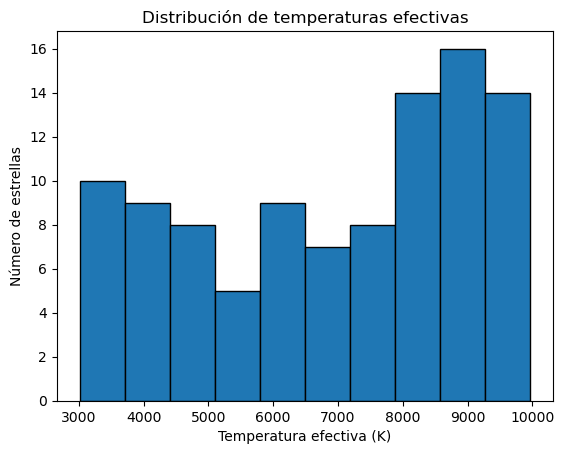

In [27]:
# Graficamos la distribución de temperaturas efectivas
plt.hist(catalogo["Temperatura efectiva (K)"], bins=10, edgecolor="black")

# Agregamos el título y los nombres de los ejes
plt.title("Distribución de temperaturas efectivas")
plt.xlabel("Temperatura efectiva (K)")
plt.ylabel("Número de estrellas")

# Guardamos el gráfico como imagen
plt.savefig("temperaturas.png", dpi=300, bbox_inches="tight")

# Mostramos el gráfico
plt.show()

<ipython-input-28-b4177cfb8be8>:10: MatplotlibDeprecationWarning: The x parameter as float was deprecated in Matplotlib 3.10 and will be removed in 3.12. Use int(x) instead.
  plt.savefig("radios.png", dpi=300, bbox_inches="tight")
<ipython-input-28-b4177cfb8be8>:10: MatplotlibDeprecationWarning: The y parameter as float was deprecated in Matplotlib 3.10 and will be removed in 3.12. Use int(y) instead.
  plt.savefig("radios.png", dpi=300, bbox_inches="tight")


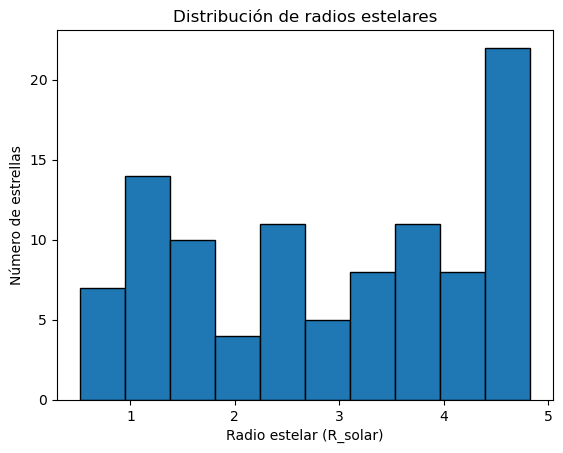

In [28]:
# Graficamos la distribución de radios estelares
plt.hist(catalogo["Radio estelar (R_solar)"], bins=10, edgecolor="black")

# Agregamos el título y los nombres de los ejes
plt.title("Distribución de radios estelares")
plt.xlabel("Radio estelar (R_solar)")
plt.ylabel("Número de estrellas")

# Guardamos el gráfico como imagen
plt.savefig("radios.png", dpi=300, bbox_inches="tight")

# Mostramos el gráfico
plt.show()

<ipython-input-29-c4950b5edb65>:10: MatplotlibDeprecationWarning: The x parameter as float was deprecated in Matplotlib 3.10 and will be removed in 3.12. Use int(x) instead.
  plt.savefig("distancias.png", dpi=300, bbox_inches="tight")
<ipython-input-29-c4950b5edb65>:10: MatplotlibDeprecationWarning: The y parameter as float was deprecated in Matplotlib 3.10 and will be removed in 3.12. Use int(y) instead.
  plt.savefig("distancias.png", dpi=300, bbox_inches="tight")


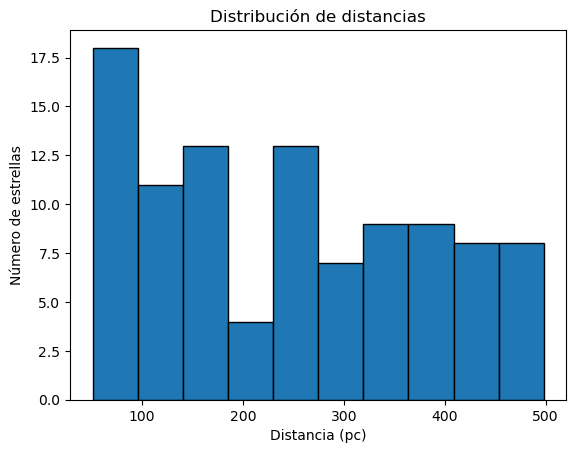

In [29]:
# Graficamos la distribución de distancias
plt.hist(catalogo["Distancia (pc)"], bins=10, edgecolor="black")

# Agregamos el título y los nombres de los ejes
plt.title("Distribución de distancias")
plt.xlabel("Distancia (pc)")
plt.ylabel("Número de estrellas")

# Guardamos el gráfico como imagen
plt.savefig("distancias.png", dpi=300, bbox_inches="tight")

# Mostramos el gráfico
plt.show()

<ipython-input-30-f36ed93cf251>:10: MatplotlibDeprecationWarning: The x parameter as float was deprecated in Matplotlib 3.10 and will be removed in 3.12. Use int(x) instead.
  plt.savefig("luminosidades.png", dpi=300, bbox_inches="tight")
<ipython-input-30-f36ed93cf251>:10: MatplotlibDeprecationWarning: The y parameter as float was deprecated in Matplotlib 3.10 and will be removed in 3.12. Use int(y) instead.
  plt.savefig("luminosidades.png", dpi=300, bbox_inches="tight")


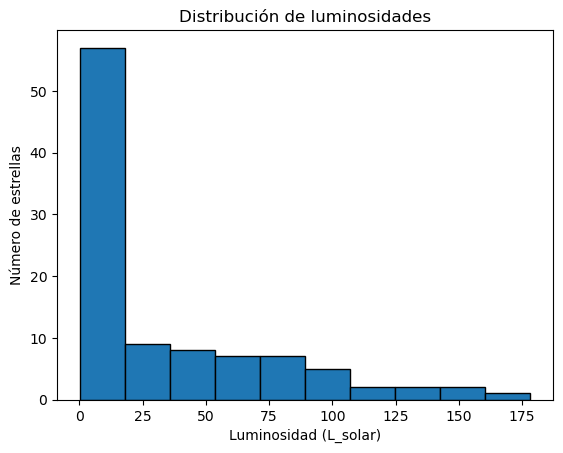

In [30]:
# Graficamos la distribución de luminosidades
plt.hist(catalogo["Luminosidad (L_solar)"], bins=10, edgecolor="black")

# Agregamos el título y los nombres de los ejes
plt.title("Distribución de luminosidades")
plt.xlabel("Luminosidad (L_solar)")
plt.ylabel("Número de estrellas")

# Guardamos el gráfico como imagen
plt.savefig("luminosidades.png", dpi=300, bbox_inches="tight")

# Mostramos el gráfico
plt.show()

<ipython-input-31-fcbc56c777df>:10: MatplotlibDeprecationWarning: The x parameter as float was deprecated in Matplotlib 3.10 and will be removed in 3.12. Use int(x) instead.
  plt.savefig("flujos.png", dpi=300, bbox_inches="tight")
<ipython-input-31-fcbc56c777df>:10: MatplotlibDeprecationWarning: The y parameter as float was deprecated in Matplotlib 3.10 and will be removed in 3.12. Use int(y) instead.
  plt.savefig("flujos.png", dpi=300, bbox_inches="tight")


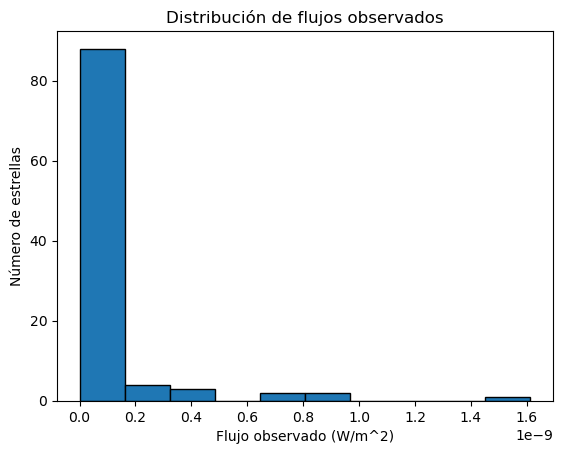

In [31]:
# Graficamos la distribución de flujos observados
plt.hist(catalogo["Flujo observado (W/m^2)"], bins=10, edgecolor="black")

# Agregamos el título y los nombres de los ejes
plt.title("Distribución de flujos observados")
plt.xlabel("Flujo observado (W/m^2)")
plt.ylabel("Número de estrellas")

# Guardamos el gráfico como imagen
plt.savefig("flujos.png", dpi=300, bbox_inches="tight")

# Mostramos el gráfico
plt.show()

<ipython-input-32-134ee5d5ac08>:29: MatplotlibDeprecationWarning: The width parameter as float was deprecated in Matplotlib 3.10 and will be removed in 3.12. Use int(width) instead.
  plt.savefig("flujo_distancia.png", dpi=300)
<ipython-input-32-134ee5d5ac08>:29: MatplotlibDeprecationWarning: The height parameter as float was deprecated in Matplotlib 3.10 and will be removed in 3.12. Use int(height) instead.
  plt.savefig("flujo_distancia.png", dpi=300)
<ipython-input-32-134ee5d5ac08>:29: MatplotlibDeprecationWarning: The x parameter as float was deprecated in Matplotlib 3.10 and will be removed in 3.12. Use int(x) instead.
  plt.savefig("flujo_distancia.png", dpi=300)
<ipython-input-32-134ee5d5ac08>:29: MatplotlibDeprecationWarning: The y parameter as float was deprecated in Matplotlib 3.10 and will be removed in 3.12. Use int(y) instead.
  plt.savefig("flujo_distancia.png", dpi=300)


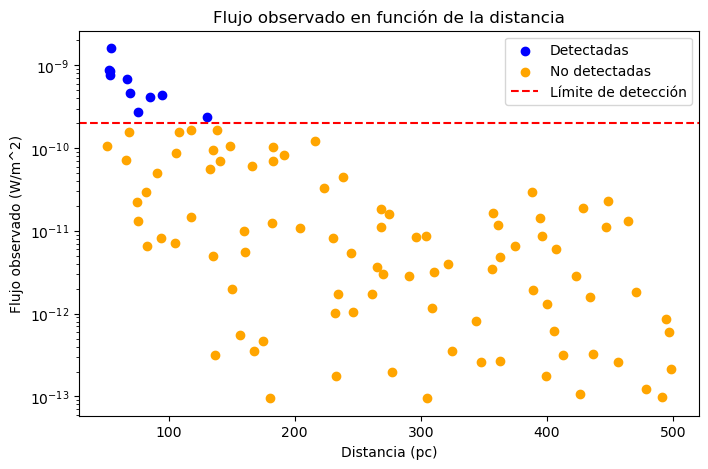

In [32]:
# Creamos una figura para el gráfico
plt.figure(figsize=(8, 5), dpi=100)

# Separamos las estrellas según su clasificación
detectadas = catalogo[catalogo["Clasificacion"] == "Detectada"]
no_detectadas = catalogo[catalogo["Clasificacion"] == "No detectada"]

# Graficamos las estrellas detectadas y no detectadas
plt.scatter(detectadas["Distancia (pc)"],
            detectadas["Flujo observado (W/m^2)"],
            color="blue", label="Detectadas")

plt.scatter(no_detectadas["Distancia (pc)"],
            no_detectadas["Flujo observado (W/m^2)"],
            color="orange", label="No detectadas")

# Agregamos el límite de detección
plt.axhline(F_lim, color="red", linestyle="--",
            label="Límite de detección")

# Configuramos el gráfico
plt.title("Flujo observado en función de la distancia")
plt.xlabel("Distancia (pc)")
plt.ylabel("Flujo observado (W/m^2)")
plt.yscale("log")
plt.legend()

# Guardamos y mostramos el gráfico
plt.savefig("flujo_distancia.png", dpi=300)
plt.show()

<ipython-input-33-0fa05bb319ee>:26: MatplotlibDeprecationWarning: The width parameter as float was deprecated in Matplotlib 3.10 and will be removed in 3.12. Use int(width) instead.
  plt.savefig("luminosidad_temperatura.png", dpi=300)
<ipython-input-33-0fa05bb319ee>:26: MatplotlibDeprecationWarning: The height parameter as float was deprecated in Matplotlib 3.10 and will be removed in 3.12. Use int(height) instead.
  plt.savefig("luminosidad_temperatura.png", dpi=300)
<ipython-input-33-0fa05bb319ee>:26: MatplotlibDeprecationWarning: The x parameter as float was deprecated in Matplotlib 3.10 and will be removed in 3.12. Use int(x) instead.
  plt.savefig("luminosidad_temperatura.png", dpi=300)
<ipython-input-33-0fa05bb319ee>:26: MatplotlibDeprecationWarning: The y parameter as float was deprecated in Matplotlib 3.10 and will be removed in 3.12. Use int(y) instead.
  plt.savefig("luminosidad_temperatura.png", dpi=300)


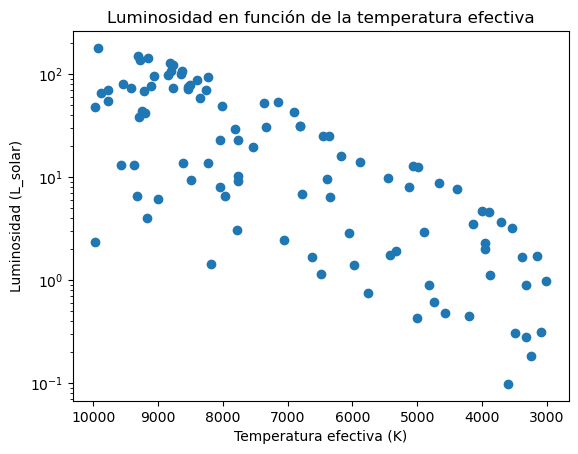

In [33]:
# Ordenamos las estrellas por temperatura, de mayor a menor
catalogo_ordenado = catalogo.sort_values(
    by="Temperatura efectiva (K)",
    ascending=False
)

# Graficamos la luminosidad en función de la temperatura
plt.plot(
    catalogo_ordenado["Temperatura efectiva (K)"],
    catalogo_ordenado["Luminosidad (L_solar)"],
    marker="o",
    linestyle="none"
)

# Configuramos el título, los ejes y la escala logarítmica
plt.title("Luminosidad en función de la temperatura efectiva")
plt.xlabel("Temperatura efectiva (K)")
plt.ylabel("Luminosidad (L_solar)")
plt.yscale("log")

# Invertimos el eje horizontal para mostrar temperaturas de mayor a menor
plt.gca().invert_xaxis()


# Guardamos el gráfico como imagen
plt.savefig("luminosidad_temperatura.png", dpi=300)

# Mostramos el gráfico
plt.show()